<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-01/lab-002-numpy.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 002 — NumPy basics

In the lecture we said: *a neural network is a non-linear, parametrised function with a nested structure*,
$$f_{\vec\theta}(\mathbf{x}) = h^{(L)}\circ\cdots\circ h^{(1)}(\mathbf{x}), \qquad h^{(l)}(\mathbf{z}) = \sigma\big(\mathbf{W}^{(l)}\mathbf{z} + \mathbf{b}^{(l)}\big). \tag{1}$$
Here $\circ$ denotes composition of functions,
$$g\circ h(\mathbf x) = g(h(\mathbf x)) , \tag{2}$$
so the output of one layer $h^{(l)}$ is the input of the next. $\sigma$ is an activation function, a fixed non-linear function applied to every component separately (examples in Section 9).
Every ingredient here — vectors $\mathbf z$, matrices $\mathbf W$, element-wise functions $\sigma$ — is an **array operation**.
NumPy is the Python library for arrays. PyTorch uses almost the same interface, so NumPy code carries over to PyTorch with minor changes of names.

Section 1 measures why arrays are worth the trouble: a loop over a million numbers against a single vectorised expression.
Sections 2–6 then cover the everyday operations: creating arrays, indexing, slicing and boolean masks, reshaping and stacking, broadcasting, and reductions along an axis.
Section 7 applies linear algebra to a physics problem, the Schrödinger equation on a grid, and Section 8 introduces random numbers and a Monte Carlo estimate of $\pi$.
In Section 9 these pieces are combined into a dense layer of a neural network, and Section 10 explains the limits of NumPy that motivate PyTorch.
Section 11 summarises the operations, and Section 12 contains exercises with solutions.

> The notebook runs in Google Colab without any installation:
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `matplotlib`) are pre-installed in Colab; no `pip install` required.
> 4. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

# Display settings only (the stored numbers are not changed): 4 digits after the decimal point,
# and tiny numbers such as 1e-17 are printed as 0. instead of in scientific notation.
np.set_printoptions(precision=4, suppress=True)
print("NumPy version:", np.__version__)

NumPy version: 2.1.3


<hr/>
## 1. Loops and vectorisation

We compute the sum of squares
$$S = \sum_{i=1}^{n} x_i^2 \tag{3}$$
for a million numbers, first with a Python loop, then with NumPy, and time both with `time.perf_counter()`.
The value of $n$ only has to be large enough that both run times are well above the resolution of the clock.

In [2]:
n = 1_000_000
x_list = [i / n for i in range(n)]          # a Python list
x_arr = np.array(x_list)                    # the same numbers as a NumPy array

t0 = time.perf_counter()
s = 0.0
for xi in x_list:                           # explicit Python loop
    s += xi**2
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
s_np = np.sum(x_arr**2)                     # one vectorised expression
t_np = time.perf_counter() - t0

print(f"loop : {s:.6f}   time {t_loop*1e3:7.2f} ms")
print(f"numpy: {s_np:.6f}   time {t_np*1e3:7.2f} ms   -> {t_loop/t_np:.0f}x faster")

loop : 333332.833334   time  237.06 ms
numpy: 333332.833333   time    6.32 ms   -> 38x faster


The measured ratio depends on the computer and changes from run to run; in the run stored above, NumPy was about 40 times faster for a million numbers.
The last digit of the two sums differs because the two methods add the numbers in a different order; floating-point rounding depends on the order, and both are correct to about $10^{-12}$ relative accuracy.

The speed difference comes from the memory layout. A NumPy array is a contiguous block of memory holding numbers of *one* type; the loop over it runs inside NumPy, in code implemented in the language C and translated to machine instructions in advance (*compiled*).
A Python list holds references to separate Python objects, each of which may be of a different type, and the Python loop is executed statement by statement by the Python interpreter, which checks the type of every element anew.

> A `for` loop over the *elements* of an array can almost always be replaced by a shorter and faster NumPy expression.

<hr/>
## 2. Creating arrays

Every array carries three attributes: `a.shape` is the size along each axis (a tuple), `a.ndim` is the number of axes,
and `a.dtype` is the type of the elements (`float64`, `int64`, `complex128`, `bool`, ...).

In [3]:
a = np.array([1.0, 2.0, 3.0])                 # 1D array (a vector)
M = np.array([[1, 2, 3],
              [4, 5, 6]])                    # 2D array (a matrix): a list of rows

for name, arr in [("a", a), ("M", M)]:
    print(f"{name}: shape={arr.shape}, ndim={arr.ndim}, dtype={arr.dtype}")

a: shape=(3,), ndim=1, dtype=float64
M: shape=(2, 3), ndim=2, dtype=int64


NumPy offers several constructors for common arrays. Mind the difference between `arange` (given **step**, end excluded) and `linspace` (given **number of points**, end included).
For physics grids prefer `linspace`.

In [4]:
print("zeros     :", np.zeros(4))
print("ones      :", np.ones((2, 3)))             # shape given as a tuple
print("arange    :", np.arange(0, 1, 0.25))       # 0, 0.25, 0.5, 0.75   (the end point 1 is excluded)
print("linspace  :", np.linspace(0, 1, 5))        # 0, 0.25, ..., 1      (1 included)
print("identity  :\n", np.eye(3))
print("full      :", np.full(3, 7.0))
print("zeros_like:", np.zeros_like(a))            # same shape & dtype as `a`

zeros     : [0. 0. 0. 0.]
ones      : [[1. 1. 1.]
 [1. 1. 1.]]
arange    : [0.   0.25 0.5  0.75]
linspace  : [0.   0.25 0.5  0.75 1.  ]
identity  :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
full      : [7. 7. 7.]
zeros_like: [0. 0. 0.]


The dtype matters. NumPy chooses it from the entries: `M` above contains integers only and became `int64`, while `a` contains `1.0` and became `float64`. Integer arrays stay integer under `+`, `-`, `*` and `//`, but `/` always returns floats (see below); complex numbers are built in (`1j` is the imaginary unit).
The number in the name is the number of bits per element: `float64` uses 8 bytes and keeps about 16 significant digits, `float32` uses 4 bytes and keeps about 7.
Deep learning usually uses `float32` (faster, less memory), scientific computing `float64` (more precise).

In [5]:
i = np.array([1, 2, 3])
print(i.dtype, i / 2, (i / 2).dtype)              # division promotes int -> float
psi = np.array([1, 1j]) / np.sqrt(2)              # a qubit state (|0> + i|1>)/sqrt(2)
print(psi, psi.dtype, "norm^2 =", np.sum(np.abs(psi)**2))
# the squared norm is 0.9999999999999998, not exactly 1: floating-point numbers have about 16 significant digits,
# so results of arithmetic are exact only up to rounding errors of order 1e-16
print(np.float32(1/3), np.float64(1/3))           # 7 vs 16 significant digits

int64 [0.5 1.  1.5] float64
[0.7071+0.j     0.    +0.7071j] complex128 norm^2 = 0.9999999999999998
0.33333334 0.3333333333333333


<hr/>
## 3. Indexing, slicing and boolean masks

Indexing works like for lists (from 0, negative from the end, `start:stop:step`), and for 2D arrays we give one index per axis: `M[row, column]`.

In [6]:
A = np.arange(20).reshape(4, 5)     # numbers 0..19 arranged in 4 rows, 5 columns
print(A)
print("A[1, 3]    =", A[1, 3])          # row 1, column 3
print("A[0]       =", A[0])             # whole row 0
print("A[:, 2]    =", A[:, 2])          # whole column 2  (':' means 'everything')
print("A[1:3, ::2]=\n", A[1:3, ::2])    # rows 1-2, every second column
print("A[-1, -1]  =", A[-1, -1])        # last element

[[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]
 [15 16 17 18 19]]
A[1, 3]    = 8
A[0]       = [0 1 2 3 4]
A[:, 2]    = [ 2  7 12 17]
A[1:3, ::2]=
 [[ 5  7  9]
 [10 12 14]]
A[-1, -1]  = 19


**Boolean masks** select the elements that satisfy a condition.

In [7]:
x = np.linspace(-3, 3, 13)
mask = np.abs(x) < 1.5            # an array of True/False
print(mask)
print("selected:", x[mask])
y = x.copy()                      # an independent copy of x (see 'Views and copies' below)
y[x < 0] = 0.0                    # set all negative entries to zero (this is the ReLU function)
print("ReLU(x) :", y)

[False False False False  True  True  True  True  True False False False
 False]
selected: [-1.  -0.5  0.   0.5  1. ]
ReLU(x) : [0.  0.  0.  0.  0.  0.  0.  0.5 1.  1.5 2.  2.5 3. ]


### Views and copies
Basic slicing (`start:stop:step`) does **not** copy data: it returns a *view* on the same memory, and modifying the view modifies the original.
Indexing with a boolean mask (as above) or with an array of integers returns a **copy**.
`.copy()` creates an independent array.

In [8]:
a = np.arange(5)
b = a[1:4]          # a VIEW
b[0] = 100
print("a after modifying b:", a, "  <- a changed as well")

a = np.arange(5)
c = a[1:4].copy()   # an independent COPY
c[0] = 100
print("a after modifying c:", a, "  <- unchanged")

a after modifying b: [  0 100   2   3   4]   <- a changed as well
a after modifying c: [0 1 2 3 4]   <- unchanged


<hr/>
## 4. Reshaping and stacking

The same numbers can be viewed with different shapes, as long as the total size agrees. `-1` means that this dimension is inferred from the total size.
`reshape` reads the elements row by row (the last index changes fastest) and fills the new shape in the same order.
In deep learning, for example, a $28\times28$ image becomes a vector of length $784$ before entering a dense layer.

In [9]:
img = np.arange(16).reshape(4, 4)      # a tiny 4x4 "image"
vec = img.reshape(-1)                  # flatten -> shape (16,)
print(img.shape, "->", vec.shape)
print("reshaped to 2x8:\n", vec.reshape(2, -1))
print("transpose:\n", img.T)

(4, 4) -> (16,)
reshaped to 2x8:
 [[ 0  1  2  3  4  5  6  7]
 [ 8  9 10 11 12 13 14 15]]
transpose:
 [[ 0  4  8 12]
 [ 1  5  9 13]
 [ 2  6 10 14]
 [ 3  7 11 15]]


Column vs. row vectors: a 1D array of shape `(n,)` is neither. An axis is added with `None` (or `np.newaxis`) to obtain shape `(n, 1)` or `(1, n)`.
Such shapes are needed for broadcasting in the next section: combining a `(n, 1)` column with a `(1, m)` row gives an `(n, m)` table.

In [10]:
v = np.array([1.0, 2.0, 3.0])
print(v.shape, v[:, None].shape, v[None, :].shape)

(3,) (3, 1) (1, 3)


Arrays are joined with `concatenate` along an existing axis and with `stack` along a new one.

In [11]:
u, w = np.array([1, 2, 3]), np.array([4, 5, 6])
print("concatenate:", np.concatenate([u, w]))
print("stack axis 0:\n", np.stack([u, w]))           # shape (2, 3): rows
print("stack axis 1:\n", np.stack([u, w], axis=1))   # shape (3, 2): columns

concatenate: [1 2 3 4 5 6]
stack axis 0:
 [[1 2 3]
 [4 5 6]]
stack axis 1:
 [[1 4]
 [2 5]
 [3 6]]


<hr/>
## 5. Broadcasting

Arithmetic between arrays of *different* shapes works if, comparing shapes **from the right**, each pair of dimensions is either equal or one of them is 1.
If one array has fewer axes, its shape is first padded with 1s on the left: shape `(3,)` is treated as `(1, 3)`, and a scalar as shape `()`, compatible with everything.
The size-1 dimension is (virtually) repeated. No data are copied, so it is fast and memory-efficient.

| shape of `A` | shape of `B` | result |
|---|---|---|
| `(3,)` | scalar | `(3,)` |
| `(4, 3)` | `(3,)` | `(4, 3)` — `B` added to every row |
| `(4, 1)` | `(1, 3)` | `(4, 3)` — an "outer" operation |
| `(4, 3)` | `(4,)` | error (3 ≠ 4) — use `B[:, None]` |

In [12]:
# 4 students (samples) x 3 features: height [m], mass [kg], age [years] (very different scales)
X = np.array([[1.62, 55.0, 19.0],
              [1.80, 82.0, 23.0],
              [1.75, 70.0, 21.0],
              [1.68, 61.0, 30.0]])
mean = X.mean(axis=0)                            # axis=0: average over the rows (samples), one mean per feature, shape (3,)
std = X.std(axis=0)                              # divides by N (np.std default); X.std(axis=0, ddof=1) divides by N-1
X_normalised = (X - mean) / std                  # (4,3) with (3,) -> broadcast over rows
print(X_normalised)
print("feature means now:", X_normalised.mean(axis=0), "  stds now:", X_normalised.std(axis=0))
# Standardising features like this is a standard preprocessing step before training a network.

[[-1.3538 -1.1795 -1.0251]
 [ 1.2806  1.4744 -0.0603]
 [ 0.5488  0.2949 -0.5427]
 [-0.4756 -0.5898  1.6282]]
feature means now: [0. 0. 0.]   stds now: [1. 1. 1.]


Broadcasting also gives "outer" operations without loops, for example a table of $\sin(k x)$ for many $k$ and many $x$ at once. The result `modes` has shape `(4, 200)`: element `[i, j]` is $\sin(k_i x_j)$, so row `i` is the whole curve for wave number $k_i$ (iterating over a 2D array gives its rows).

(4, 200)


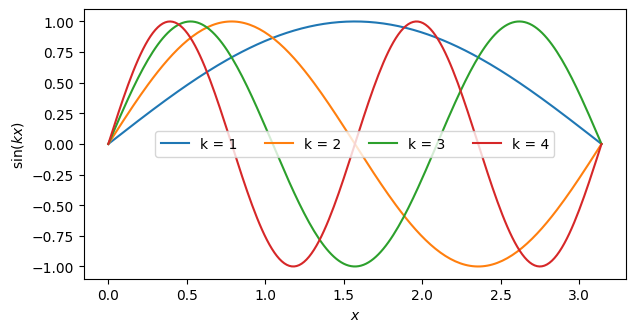

In [13]:
x = np.linspace(0, np.pi, 200)          # shape (200,)
k = np.arange(1, 5)                     # shape (4,)
modes = np.sin(k[:, None] * x[None, :]) # (4,1) * (1,200) -> (4,200)
print(modes.shape)

fig, ax = plt.subplots(figsize=(7, 3.5))
for kk, row in zip(k, modes):
    ax.plot(x, row, label=f"k = {kk}")
ax.set_xlabel("$x$"); ax.set_ylabel(r"$\sin(kx)$"); ax.legend(ncol=4)
plt.show()

<hr/>
## 6. Reductions along an axis

`sum`, `mean`, `std`, `max`, `argmax`, ... collapse an array along an axis.
Convention: **axis 0 = samples, axis 1 = features** (the same in PyTorch, where the argument is called `dim`; here the features are the classes). `axis=k` is the axis that is removed by the reduction.
`scores` has shape `(4, 3)` (4 samples, 3 classes): `sum(axis=1)` removes the class axis and returns shape `(4,)`, one number per sample; `mean(axis=0)` removes the sample axis and returns shape `(3,)`, one number per class.
`argmax` returns the *position* of the largest element, counted from 0.
`keepdims=True` keeps the reduced axis with size 1, e.g. `scores.sum(axis=1, keepdims=True)` has shape `(4, 1)`, ready for broadcasting against `scores`.

In [14]:
scores = np.array([[0.1, 0.7, 0.2],      # e.g. network outputs for 4 images and 3 classes
                   [0.8, 0.1, 0.1],
                   [0.3, 0.3, 0.4],
                   [0.05, 0.9, 0.05]])
print("sum over classes (axis=1):", scores.sum(axis=1))      # each row sums to 1 -> probabilities
print("mean over samples (axis=0):", scores.mean(axis=0))
print("predicted class (argmax):  ", scores.argmax(axis=1))

sum over classes (axis=1): [1. 1. 1. 1.]
mean over samples (axis=0): [0.3125 0.5    0.1875]
predicted class (argmax):   [1 0 2 1]


<hr/>
## 7. Linear algebra

`@` is matrix multiplication; `np.linalg` contains solvers, determinants, eigenvalue routines.

In [15]:
M = np.array([[2.0, 1.0], [1.0, 3.0]])
v = np.array([1.0, -1.0])
print("M @ v   =", M @ v)            # matrix-vector product
print("v @ v   =", v @ v)            # scalar product
print("M * M   =\n", M * M)          # element-wise (not the matrix product)
print("M @ M   =\n", M @ M)          # matrix product
x_sol = np.linalg.solve(M, v)        # the vector x with M @ x = v (without computing the inverse of M)
print("solve M x = v :", x_sol, "  check M @ x =", M @ x_sol)

M @ v   = [ 1. -2.]
v @ v   = 2.0
M * M   =
 [[4. 1.]
 [1. 9.]]
M @ M   =
 [[ 5.  5.]
 [ 5. 10.]]
solve M x = v : [ 0.8 -0.6]   check M @ x = [ 1. -1.]


### The Schrödinger equation on a grid
The eigenstates of the quantum harmonic oscillator follow from a matrix diagonalisation.
We discretise the interval $[-a, a]$ with $N_x$ points $x_1,\dots,x_{N_x}$ and the spacing
$$\Delta x = \frac{2a}{N_x-1}, \tag{4}$$
and store the values $\psi_i$ of the wavefunction at the grid points as a vector $\vec\psi$ of length $N_x$. Adding the Taylor expansions
$$\psi(x\pm\Delta x) = \psi \pm \Delta x\,\psi' + \tfrac12\Delta x^2\psi'' \pm \tfrac16\Delta x^3\psi''' + O(\Delta x^4), \tag{5}$$
the odd terms cancel and the second derivative becomes
$$\frac{d^2\psi}{dx^2}\Big|_{x_i} \approx \frac{\psi_{i+1} - 2\psi_i + \psi_{i-1}}{\Delta x^2}, \tag{6}$$
so the Hamiltonian
$$\hat H = -\tfrac12\frac{d^2}{dx^2} + V(x), \tag{7}$$
in units in which $\hbar$, $m$ and $\omega$ are one, becomes an $N_x\times N_x$ **tridiagonal matrix**
$$\bar H = -\frac{1}{2\Delta x^2}\begin{pmatrix}-2 & 1 & & \\ 1 & -2 & 1 & \\ & \ddots & \ddots & \ddots \\ & & 1 & -2\end{pmatrix} + \mathrm{diag}\big(V(x_1),\dots,V(x_{N_x})\big). \tag{8}$$
The time-independent Schrödinger equation,
$$\bar H\vec\psi_n = E_n\vec\psi_n , \tag{9}$$
is now a matrix **eigenvalue problem** — `np.linalg.eigh` (for Hermitian matrices) solves it. For the harmonic potential
$$V(x) = \tfrac12 x^2 \tag{10}$$
we expect
$$E_n = n + \tfrac12 . \tag{11}$$

Two approximations are made: the matrix ends at the first and last grid point, which means that $\psi$ vanishes outside the grid (a box with hard walls, harmless if the box is much larger than the wavefunctions), and the second derivative is replaced by a finite difference with an error of order $\Delta x^2$.

The grid has to be chosen with the physics in mind. The classical turning point of a state with energy $E$ is
$$x_t = \sqrt{2E}, \tag{12}$$
which is 3 for the highest state we show, of energy 4.5. Beyond $x_t$ the wavefunction decays quickly, so the box $[-6, 6]$, twice as wide, does not disturb the five lowest states. With 400 points the spacing $\Delta x$ is about 0.03. Both numbers are a choice, not a requirement: any half-width of 5 or more and a few hundred points give the same picture. A box $[-4, 4]$ is already too small for the state of energy 4.5 (its energy then comes out too high by about 0.008).

`np.diag(v, k)` with a 1D array `v` builds a square matrix with `v` on the $k$-th diagonal ($k$ of $\pm1$ for the off-diagonals, which are therefore one element shorter than the main diagonal).
`np.linalg.eigh` diagonalises a symmetric (Hermitian) matrix. It returns real eigenvalues sorted in ascending order and orthonormal eigenvectors. The general routine `np.linalg.eig` does not use the symmetry: it is slower, does not sort the eigenvalues and can return them with tiny imaginary parts caused by rounding. For a Hamiltonian, `eigh` is the right choice.
The matrix is stored as a full $400\times400$ array, although almost all entries are zero; diagonalising it takes about 0.02 s. The cost of full diagonalisation grows like $N_x^3$ (about 1 s for 2000 points on the same computer), so for much larger grids sparse matrices (`scipy.sparse`) are used.

In [16]:
def hamiltonian(x, V):
    """Finite-difference Hamiltonian -1/2 d^2/dx^2 + V(x) on the uniform grid x."""
    dx = x[1] - x[0]
    n = x.size
    kinetic = -0.5 / dx**2 * (np.diag(np.ones(n - 1), k=1)     # upper diagonal
                              - 2 * np.eye(n)                  # main diagonal
                              + np.diag(np.ones(n - 1), k=-1))  # lower diagonal
    return kinetic + np.diag(V)

x = np.linspace(-6, 6, 400)
H = hamiltonian(x, 0.5 * x**2)
E, psi = np.linalg.eigh(H)           # eigenvalues (ascending) and eigenvectors (as columns)
print("lowest energies:", E[:5])
print("expected       :", np.arange(5) + 0.5)

lowest energies: [0.5    1.4999 2.4996 3.4993 4.4988]
expected       : [0.5 1.5 2.5 3.5 4.5]


The computed energies lie slightly **below** the exact values (11): by about $3\times10^{-5}$ for the ground state and about $1.2\times10^{-3}$ for the fifth state (the printout shows 4 digits after the decimal point). This is the error of the finite-difference formula, of order $\Delta x^2$. With 200 points ($\Delta x$ twice as large) the errors are about 4 times larger, with 800 points about 4 times smaller, as expected for an error quadratic in $\Delta x$. Higher states oscillate faster, so the finite difference describes them less accurately.

The eigenvectors are the **columns** `psi[:, n]`, drawn as eigenfunctions shifted by their energies inside the potential.
Three details matter. The first is normalisation: `eigh` returns vectors with
$$\sum_i |\psi_i|^2 = 1, \tag{13}$$
while the wavefunction of the continuum problem must satisfy
$$\int|\psi(x)|^2dx \approx \sum_i|\psi_i|^2\,\Delta x = 1, \tag{14}$$
so the vector is divided by $\sqrt{\Delta x}$.
The second is the sign: an eigenvector is fixed only up to a factor $-1$, so `eigh` may return $-\psi_n$ and a curve can appear upside down compared with a textbook figure. Densities $|\psi_n|^2$ do not depend on this sign.
The third is the scale: each curve is multiplied by 0.6 and shifted to the height of its energy; the factor 0.6 only keeps neighbouring curves from overlapping. The vertical size of a wavefunction in such a plot has no physical meaning.

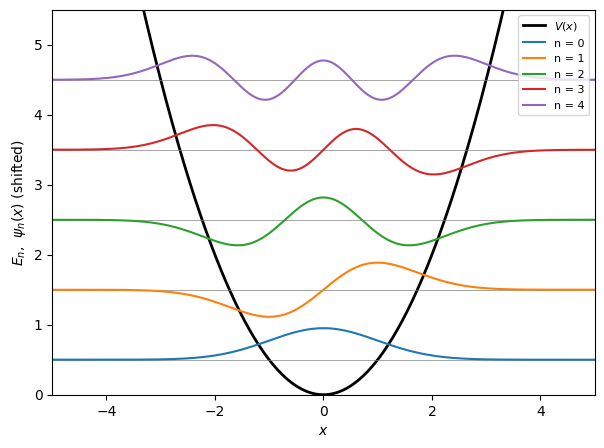

In [17]:
dx = x[1] - x[0]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, 0.5 * x**2, "k", lw=2, label="$V(x)$")
for n in range(5):
    psi_n = psi[:, n] / np.sqrt(dx)              # normalise so that sum |psi|^2 dx = 1
    ax.axhline(E[n], color="gray", lw=0.5)
    ax.plot(x, E[n] + 0.6 * psi_n, label=f"n = {n}")
ax.set_ylim(0, 5.5); ax.set_xlim(-5, 5)
ax.set_xlabel("$x$"); ax.set_ylabel(r"$E_n$,  $\psi_n(x)$ (shifted)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

<hr/>
## 8. Random numbers

Machine learning uses random numbers in several places: random initialisation of weights, random mini-batches, random noise in data.
A **generator with a fixed seed** makes the results reproducible: the same seed always gives the same sequence of numbers. Different seeds give different but statistically equivalent results.

As with `arange`, the upper end of a range is excluded: `rng.integers(0, 10)` returns integers 0, ..., 9, and `rng.random()` returns numbers in $[0, 1)$.

In [18]:
rng = np.random.default_rng(seed=123)

print("uniform [0,1):", rng.random(3))
print("normal N(0,1):", rng.normal(size=3))
print("integers     :", rng.integers(0, 10, size=5))
print("choice ±1    :", rng.choice([-1, 1], size=8))          # e.g. random Ising spins
print("permutation  :", rng.permutation(6))                   # shuffling a dataset

uniform [0,1): [0.6824 0.0538 0.2204]
normal N(0,1): [0.194  0.9202 0.5771]
integers     : [4 9 4 2 7]
choice ±1    : [ 1  1  1 -1  1 -1 -1 -1]
permutation  : [5 2 4 1 0 3]


Random numbers give a Monte Carlo estimate of $\pi$ in one line: the fraction of random points in the unit square that fall inside the quarter circle estimates its area $\pi/4$.
The error decreases like the inverse square root of $N$,
$$\text{error}\propto N^{-1/2}, \tag{15}$$
a straight line of slope $-1/2$ on a log-log plot.
The sample sizes, from `np.logspace(2, 7, 11)`, are spaced evenly in the exponent from $10^2$ to $10^7$.
Since `True` counts as 1 in arithmetic, `np.mean` of the boolean array `np.sum(pts**2, axis=1) < 1.0` is the fraction of points inside the quarter circle.
The largest sample, an array of shape $(10^7, 2)$, occupies 160 MB and is processed in well under a second.

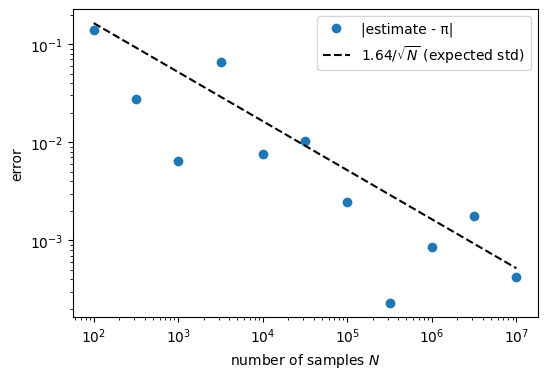

In [19]:
Ns = np.logspace(2, 7, 11).astype(int)
errors = []
for N in Ns:
    pts = rng.random((N, 2))                               # N points, 2 coordinates
    pi_est = 4 * np.mean(np.sum(pts**2, axis=1) < 1.0)
    errors.append(abs(pi_est - np.pi))

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(Ns, errors, "o", label="|estimate - π|")
# standard deviation of the estimate: 4 * sqrt(p (1 - p) / N) with p = pi/4, i.e. about 1.64 / sqrt(N)
ax.loglog(Ns, 1.64 / np.sqrt(Ns), "k--", label=r"$1.64/\sqrt{N}$ (expected std)")
ax.set_xlabel("number of samples $N$"); ax.set_ylabel("error"); ax.legend()
plt.show()

The dashed line follows from the binomial distribution. Each random point falls inside the quarter circle with the probability
$$p = \frac{\pi}{4}, \tag{16}$$
independently of the others. The fraction of hits among $N$ points and the estimate of $\pi$, four times this fraction, have the standard deviations
$$\sigma_{\rm fraction} = \sqrt{\frac{p(1-p)}{N}},\qquad \sigma_{\pi} = 4\sqrt{\frac{p(1-p)}{N}} \approx \frac{1.64}{\sqrt N}. \tag{17}$$

Each point is the result of **one** random experiment, so the points scatter around the dashed line instead of lying on it. The dashed line is the standard deviation, a typical size of the error, not an upper bound: on average $|\text{error}|$ is about 0.8 of the standard deviation, and in about a quarter of the experiments it is less than 0.3 of it. What the plot confirms is the slope: the cloud of points follows the line over five decades of $N$.

<hr/>
## 9. A dense layer in NumPy

A dense (fully connected) layer maps an input vector of size $n_\text{in}$ to an output vector of size $n_\text{out}$,
$$\mathbf z \mapsto \sigma(\mathbf W\mathbf z + \mathbf b),\qquad \mathbb R^{n_\text{in}}\to\mathbb R^{n_\text{out}}. \tag{18}$$
In practice we process a whole **batch** of $B$ inputs at once, stored as rows of a matrix of shape `(B, n_in)`. Then
$$\underbrace{\mathbf Z_\text{out}}_{(B,\,n_\text{out})} = \sigma\Big(\underbrace{\mathbf Z_\text{in}}_{(B,\,n_\text{in})}\;\underbrace{\mathbf W^{T}}_{(n_\text{in},\,n_\text{out})} + \underbrace{\mathbf b}_{(n_\text{out},)}\Big) \tag{19}$$
— one matrix product plus broadcasting of the bias. (We store `W` with shape `(n_out, n_in)`, exactly like PyTorch does.)

The activation functions from the lecture are one-line functions. ReLU is `np.maximum(0.0, z)`, the element-wise maximum, not to be confused with `np.max(z)`, the single largest element of an array.
The range $[-5, 5]$ shows where sigmoid and tanh saturate.

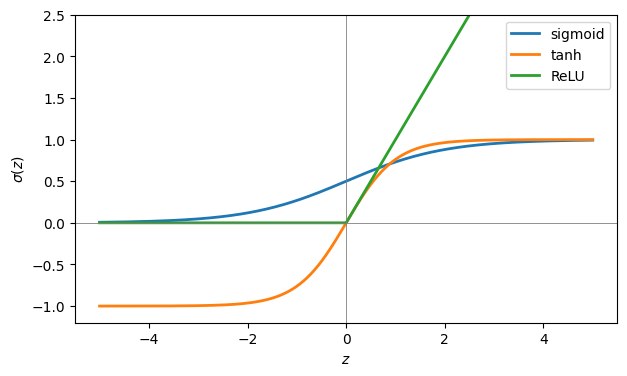

In [20]:
def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))
def tanh(z):    return np.tanh(z)
def relu(z):    return np.maximum(0.0, z)

z = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(figsize=(7, 4))
for f, name in [(sigmoid, "sigmoid"), (tanh, "tanh"), (relu, "ReLU")]:
    ax.plot(z, f(z), label=name, lw=2)
ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
ax.set_ylim(-1.2, 2.5); ax.set_xlabel("$z$"); ax.set_ylabel(r"$\sigma(z)$"); ax.legend()
plt.show()

A dense layer applied to a batch gives a random network $1\to20\to1$, evaluated on 300 inputs.

`rng.normal(0, 3, (n_hidden, n_in))` draws normally distributed numbers; the three arguments are the mean, the **standard deviation** (not the variance) and the shape of the returned array.
Hidden neuron $i$ computes
$$h_i(x) = \tanh(W_i x + b_i). \tag{20}$$
It switches between $-1$ and $+1$ (upwards for positive $W_i$, downwards for negative) around the point
$$x_i^\ast = -\frac{b_i}{W_i}, \tag{21}$$
over an interval of width about $1/|W_i|$. Because $W_i$ and $b_i$ are drawn with the same standard deviation, the switching points do not depend on that standard deviation (about 70% of them fall inside the plotted range $[-2, 2]$). The standard deviation sets how **steep** the neurons are. The value 3 is an arbitrary choice that gives visibly curved functions; with 0.3 the neurons are so flat that the network output is close to a straight line on $[-2, 2]$. Any value of order 1–5 gives a picture similar to the one below.

The output is a sum of `n_hidden` = 20 terms $W^{(2)}_i h_i$. If each term has a variance of order 1, the sum has a variance of order `n_hidden`. Dividing the output weights by $\sqrt{n_\text{hidden}}$ keeps the output of order 1 for any width. The same rule appears in Exercise 5 and in the initialisation of neural-network weights.
The linear output layer uses the identity `lambda s: s` as its "activation".

In [21]:
def dense(Z, W, b, activation):
    """One dense layer applied to a batch Z of shape (B, n_in). W: (n_out, n_in), b: (n_out,)."""
    return activation(Z @ W.T + b)

rng = np.random.default_rng(0)
n_in, n_hidden, n_out = 1, 20, 1
W1, b1 = rng.normal(0, 3, (n_hidden, n_in)), rng.normal(0, 3, n_hidden)
W2, b2 = rng.normal(0, 1, (n_out, n_hidden)) / np.sqrt(n_hidden), np.zeros(n_out)

X = np.linspace(-2, 2, 300)[:, None]       # batch of 300 one-dimensional inputs: shape (300, 1)
H1 = dense(X, W1, b1, np.tanh)             # hidden layer: (300, 20)
Y = dense(H1, W2, b2, lambda s: s)         # linear output layer: (300, 1)
print("X:", X.shape, " H1:", H1.shape, " Y:", Y.shape)

X: (300, 1)  H1: (300, 20)  Y: (300, 1)


Six sets of random weights show that a randomly initialised network is a random non-linear function.
*Training* means choosing the weights so that this function matches the data.

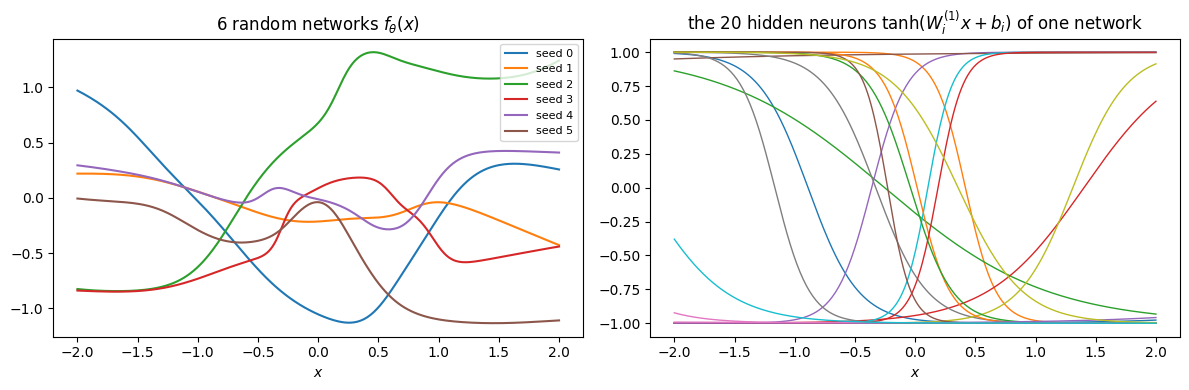

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seed in range(6):
    r = np.random.default_rng(seed)
    W1, b1 = r.normal(0, 3, (n_hidden, 1)), r.normal(0, 3, n_hidden)
    W2 = r.normal(0, 1, (1, n_hidden)) / np.sqrt(n_hidden)
    axes[0].plot(X, dense(dense(X, W1, b1, np.tanh), W2, 0.0, lambda s: s), label=f"seed {seed}")
# what the hidden neurons of the last network look like individually:
axes[1].plot(X, dense(X, W1, b1, np.tanh), lw=1)
axes[0].set_title(r"6 random networks $f_\theta(x)$"); axes[0].legend(fontsize=8)
axes[1].set_title(r"the 20 hidden neurons $\tanh(W^{(1)}_i x + b_i)$ of one network")
for ax in axes: ax.set_xlabel("$x$")
fig.tight_layout(); plt.show()

The output is a weighted sum of shifted and stretched $\tanh$'s (right panel). Sums of this form (with enough hidden neurons) can approximate any continuous function on a bounded interval to any accuracy — this is the content of the **Universal Approximation Theorem** (see the lecture).
<hr/>
## 10. Limits of NumPy

NumPy is enough to *evaluate* a network. To *train* it we need the gradient $\nabla_{\vec\theta}\mathcal L$ of the loss with respect to all parameters (the *loss* $\mathcal L(\vec\theta)$ is a single number that measures how far the network outputs are from the training data, e.g. the mean squared error; training minimises it).
NumPy does not compute derivatives. We would have to derive them ourselves on paper: for one hidden layer this is half a page,
for a network with 50 layers of different types it is not practical, and every change of the architecture would require a new derivation.

The second limitation is hardware: NumPy runs only on the CPU (central processing unit). Training large networks requires GPUs (graphics processing units, with thousands of simple arithmetic units working in parallel), which perform the same matrix
operations much faster.

Both problems are solved by **PyTorch**, which offers the same array operations as NumPy and adds two things. The first is **automatic differentiation**: the gradient of any computation is obtained with one call, `loss.backward()`.
The second is **GPU support**: the same code runs on a GPU after moving the data with `.to("cuda")`.

PyTorch (together with JAX) is the standard tool in deep-learning research and industry, and the networks of this course use it.
NumPy remains the common format for data exchange: Matplotlib, Pandas and SciPy expect NumPy arrays, so conversions between the two are frequent.
<hr/>
## 11. Summary
The central habit is to think in **arrays**, not loops, and to check shapes with `print(x.shape)`.
Grids are made with `linspace`; `reshape(-1)` flattens, `[:, None]` adds a new axis, and `.copy()` avoids surprises with views.
Broadcasting compares shapes from the right and stretches size-1 dimensions. Reductions with `axis=` remove the named axis, and by convention axis 0 holds the samples.
`@` is the matrix product while `*` is element-wise, and `np.linalg.eigh` diagonalises Hermitian matrices.
`rng = np.random.default_rng(seed)` gives reproducible randomness, and a dense layer on a batch is the single line `sigma(Z @ W.T + b)`.
<hr/>
## 12. Exercises

### Exercise 1 — Vectorised Ising energy
The energy of a classical 1D Ising chain of $L$ spins $s_i$, each $\pm1$, with periodic boundary conditions is
$$E(\mathbf s) = -J\sum_{i=1}^{L} s_i s_{i+1},\qquad s_{L+1}\equiv s_1 . \tag{22}$$
Below, `configs` holds $M$, here 10 000, random configurations as rows of an array of shape `(M, L)`.
1. A loop version is given. Write a **vectorised** version `energy_vec(configs)` without any Python loop (*hint:* `np.roll(configs, -1, axis=1)` shifts every row by one site).
2. Check both give the same result and compare the run times.
3. Plot a histogram of the energies. What are the minimal and maximal possible values?

#### Solution

same result: True | loop 0.885 s, vectorised 1.66 ms


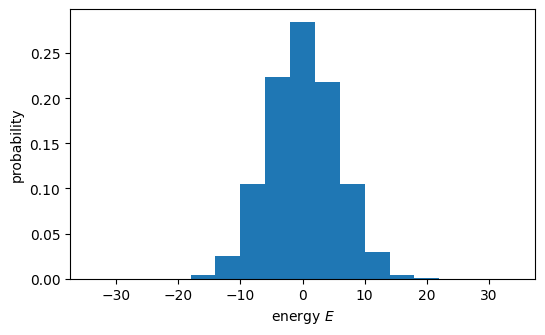

In [23]:
rng = np.random.default_rng(0)
M, L, J = 10_000, 32, 1.0
configs = rng.choice([-1, 1], size=(M, L))      # M random configurations, one per row

def energy_loop(configs):
    """Reference implementation with two explicit Python loops (slow)."""
    E = np.zeros(len(configs))
    for m in range(len(configs)):                # loop over configurations
        for i in range(L):                       # loop over bonds (i, i+1); (i+1) % L closes the ring
            E[m] -= J * configs[m, i] * configs[m, (i + 1) % L]
    return E

def energy_vec(configs):
    """Vectorised Ising energy for a batch of configurations (rows)."""
    # np.roll(configs, -1, axis=1) shifts every row by one site to the left (periodically),
    # so element [m, i] of the shifted array is s_{i+1} of configuration m.
    neighbours = np.roll(configs, -1, axis=1)
    bond_products = configs * neighbours         # s_i * s_{i+1} for all m and i at once, shape (M, L)
    return -J * np.sum(bond_products, axis=1)    # sum over the sites -> one energy per configuration

# Compare results and run times
t0 = time.perf_counter(); E1 = energy_loop(configs); t1 = time.perf_counter() - t0
t0 = time.perf_counter(); E2 = energy_vec(configs);  t2 = time.perf_counter() - t0
# np.allclose compares element by element up to a small tolerance (|a - b| <= 1e-8 + 1e-5 |b|);
# results of different but equivalent floating-point computations are compared this way, not with ==
print("same result:", np.allclose(E1, E2), f"| loop {t1:.3f} s, vectorised {t2*1e3:.2f} ms")

# Histogram. A domain wall is a bond with s_i != s_{i+1}; it contributes +J instead of -J.
# With periodic boundaries the number of domain walls n_w is even and E = -J (L - 2 n_w),
# so E takes only the values -32, -28, ..., 32. Bins of width 4 centred on these values;
# weights = 1/M make the bar heights the probabilities of the individual values.
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(E2, bins=np.arange(-L - 2, L + 3, 4), weights=np.full(M, 1 / M))
ax.set_xlabel("energy $E$"); ax.set_ylabel("probability")
plt.show()
# Minimal value: -J L (all spins aligned). Maximal: +J L (perfectly alternating; possible for even L).
# For random configurations E is a sum of L pairwise uncorrelated +-1 terms: mean 0, standard deviation sqrt(L) ~ 5.7.

### Exercise 2 — Softmax, one-hot encoding and cross-entropy
For classification the network outputs raw numbers ("logits") $\mathbf z$ which are turned into probabilities by
$$\mathrm{softmax}(\mathbf z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}} ; \tag{23}$$
the loss, as in the lecture, is the categorical cross-entropy
$$\mathcal L_\text{ce} = -\sum_i p_i\log q_i , \tag{24}$$
where $\mathbf p$ is the true distribution (for a labelled example, 1 at the true class and 0 elsewhere: the *one-hot* vector) and $\mathbf q$ the probabilities predicted by the network.
1. Implement `softmax(Z)` for a batch `Z` of shape `(B, K)` (each row normalised). Try `Z = [[1000, 1001, 1002]]` — what goes wrong? Fix it using the identity
$$\mathrm{softmax}(\mathbf z) = \mathrm{softmax}\big(\mathbf z - \max_j z_j\big). \tag{25}$$
2. Implement `one_hot(labels, K)` turning integer labels, e.g. `[2, 0, 1]`, into a `(B, K)` array of 0/1 (*hint:* `np.eye(K)[labels]`).
3. Implement `cross_entropy(P, Q)` averaged over the batch. Evaluate it for the lecture example, the true digit 2 and the prediction
$$\mathbf q = (0.1,\ 0,\ 0.7,\ 0.01,\ 0.1,\ 0.02,\ 0,\ 0.02,\ 0,\ 0.05). \tag{26}$$
   Why is it necessary to guard against $\log 0$?

#### Solution

In [24]:
def softmax(Z):
    """Row-wise softmax of a batch Z of shape (B, K)."""
    Z = np.atleast_2d(Z)                         # a single vector becomes shape (1, K)
    # Subtracting the row maximum does not change the result (it cancels between numerator and
    # denominator) but makes the largest exponent exp(0) = 1, so nothing overflows.
    Zs = Z - Z.max(axis=1, keepdims=True)        # keepdims=True keeps shape (B, 1) for broadcasting
    E = np.exp(Zs)
    return E / E.sum(axis=1, keepdims=True)

def one_hot(labels, K):
    """Integer labels (B,) -> one-hot array (B, K)."""
    # Row number l of the identity matrix is exactly the one-hot vector of label l,
    # and indexing with an array of labels picks all those rows at once.
    return np.eye(K)[labels]

def cross_entropy(P, Q, eps=1e-12):
    """Categorical cross-entropy -sum_i p_i log q_i, averaged over the batch."""
    # eps=1e-12 is a default argument: used when the caller does not pass eps. It must be much smaller
    # than any probability that matters and keep log(eps) ~ -27.6 finite; any value 1e-15 ... 1e-8 works.
    return -np.mean(np.sum(P * np.log(Q + eps), axis=1))

# 1) the naive formula overflows: exp(1000) is larger than the largest float64 (about 1.8e308)
# A `with` block applies a setting only to the indented code under it: here NumPy's overflow and
# invalid-operation warnings are switched off for the demonstration line and restored afterwards.
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp([1000., 1001., 1002.]) / np.exp([1000., 1001., 1002.]).sum()
print("naive softmax :", naive, " (overflow -> inf/inf = nan)")
print("stable softmax:", softmax([[1000., 1001., 1002.]]))

# 2) one-hot encoding
print("one-hot       :\n", one_hot(np.array([2, 0, 1]), 3))

# 3) the example from the lecture: true digit 2, network assigns probability 0.7 to it
q = np.array([[0.1, 0, 0.7, 0.01, 0.1, 0.02, 0, 0.02, 0, 0.05]])
p = one_hot(np.array([2]), 10)
print("cross-entropy :", cross_entropy(p, q), "  -log(0.7) =", -np.log(0.7))
# (the two differ at the level 1e-12 because of eps)
# Only the true class contributes, so L_ce = -log q_true.
# Without eps, entries q_i = 0 give log(0) = -inf, and 0 * (-inf) = nan in floating-point arithmetic.

naive softmax : [nan nan nan]  (overflow -> inf/inf = nan)
stable softmax: [[0.09   0.2447 0.6652]]
one-hot       :
 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]
cross-entropy : 0.3566749439373039   -log(0.7) = 0.35667494393873245


### Exercise 3 — Tunnelling in a double well
Use `hamiltonian(x, V)` from Section 7 with a harmonic trap and a Gaussian barrier,
$$V(x) = \tfrac12 x^2 + \kappa\, e^{-x^2/2}. \tag{27}$$
1. For the barrier heights 0, 2, 4 and 10 plot $V(x)$ and the densities $|\psi_n(x)|^2$ of the four lowest states ($2\times2$ subplots).
2. Plot the ground-state energy $E_0(\kappa)$ and the gap
$$\Delta E = E_1 - E_0 \tag{28}$$
   for barrier heights from 0 to 12. Use a log scale for $\Delta E$.
   Interpret: what happens to the two lowest states when the barrier grows?

#### Solution

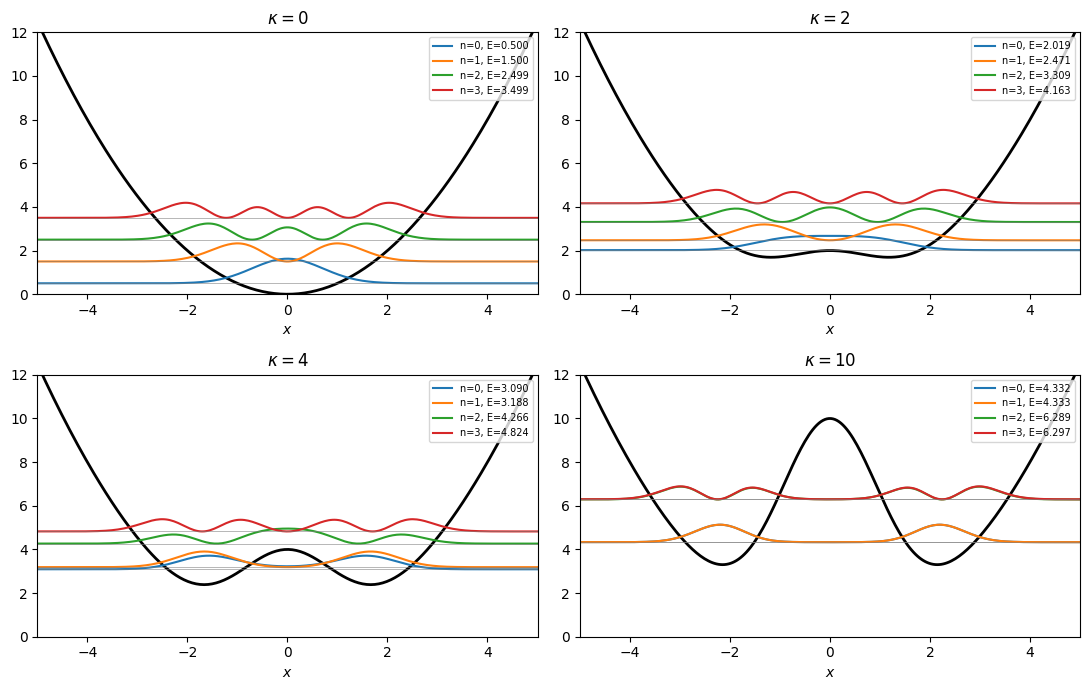

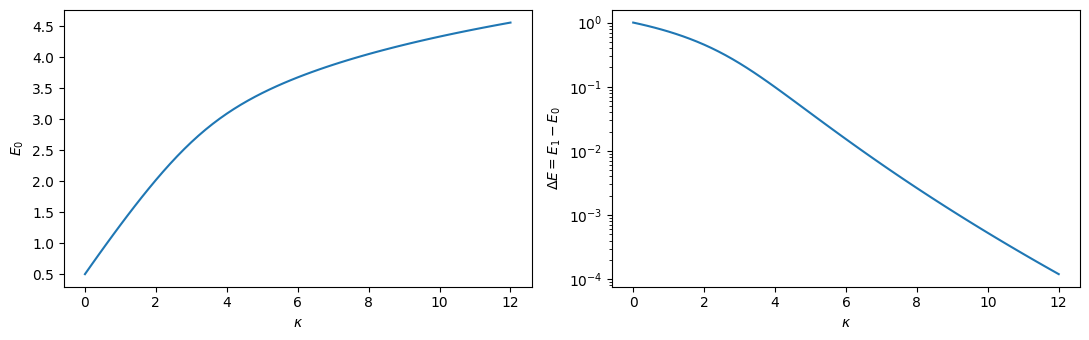

In [25]:
# 300 points instead of 400: the Hamiltonian is diagonalised 65 times below, and a smaller matrix is faster.
# The results hardly change: the gap at kappa = 10 is 5.28e-4 with 300 points and 5.27e-4 with 600 points.
x = np.linspace(-6, 6, 300)
dx = x[1] - x[0]

def V_dw(x, kappa):
    """Double well: harmonic trap plus a Gaussian barrier of height kappa."""
    return 0.5 * x**2 + kappa * np.exp(-x**2 / 2)

# Part 1: potential and the four lowest densities for four barrier heights
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
# axes is a 2x2 NumPy array of coordinate systems; flatten() turns it into a 1D sequence,
# so one loop visits all four panels
for ax, kappa in zip(axes.flatten(), [0, 2, 4, 10]):
    E, psi = np.linalg.eigh(hamiltonian(x, V_dw(x, kappa)))   # E ascending, psi[:, n] = n-th eigenvector
    ax.plot(x, V_dw(x, kappa), "k", lw=2)
    for n in range(4):
        # psi is real (the Hamiltonian is real and symmetric), so psi**2 = |psi|^2;
        # for a complex Hamiltonian np.abs(psi)**2 would be needed
        density = psi[:, n]**2 / dx                           # normalised so that sum(density) * dx = 1
        ax.plot(x, E[n] + 2 * density, label=f"n={n}, E={E[n]:.3f}")   # shifted by E_n, scaled by 2 to be visible
        ax.axhline(E[n], color="gray", lw=0.4)
    ax.set_ylim(0, 12); ax.set_xlim(-5, 5); ax.set_title(rf"$\kappa = {kappa}$")
    ax.set_xlabel("$x$"); ax.legend(fontsize=7, loc="upper right")
fig.tight_layout(); plt.show()

# Part 2: E_0 and the gap as functions of kappa. eigvalsh computes only eigenvalues (faster than eigh).
kappas = np.linspace(0, 12, 61)
E0, gap = [], []
for kappa in kappas:
    E = np.linalg.eigvalsh(hamiltonian(x, V_dw(x, kappa)))
    E0.append(E[0])
    gap.append(E[1] - E[0])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(kappas, E0); axes[0].set_ylabel("$E_0$")
axes[1].semilogy(kappas, gap); axes[1].set_ylabel(r"$\Delta E = E_1 - E_0$")
for ax in axes: ax.set_xlabel(r"$\kappa$")
fig.tight_layout(); plt.show()
# For kappa = 0 the gap is 1 (harmonic oscillator). As the barrier grows, E_0 and E_1 approach each other
# and for large barriers (kappa >~ 4) the gap decreases roughly exponentially (a straight line on the log plot). The two states become the
# symmetric and antisymmetric combinations of states localised in the left and right well; the small gap is
# the tunnelling splitting.
# Even the smallest gap, about 1.2e-4 at kappa = 12, is far above the rounding error of eigvalsh
# (about 1e-16 times the largest eigenvalue of H, i.e. of order 1e-13), so the log plot is reliable.

### Exercise 4 — Pairwise distances with broadcasting
200 particles sit at random positions in a 2D box $[0, 10]^2$ (array `R` of shape `(N, 2)`).
1. Compute the matrix of all pairwise distances
$$d_{ij} = |\mathbf r_i - \mathbf r_j| \tag{29}$$
   **without loops** (*hint:* `R[:, None, :] - R[None, :, :]` has shape `(N, N, 2)`).
2. The Lennard-Jones pair potential is
$$V_\text{LJ}(d) = 4\epsilon\Big[\Big(\frac{\sigma_\text{LJ}}{d}\Big)^{12} - \Big(\frac{\sigma_\text{LJ}}{d}\Big)^{6}\Big], \tag{30}$$
   with $\epsilon$ the well depth and $\sigma_\text{LJ}$ the distance at which $V_\text{LJ}$ vanishes. In reduced units (lengths in units of $\sigma_\text{LJ}$, energies in units of $\epsilon$) compute the total Lennard-Jones energy
$$E = \sum_{i<j} 4\Big[\Big(\frac{1}{d_{ij}}\Big)^{12} - \Big(\frac{1}{d_{ij}}\Big)^{6}\Big] \tag{31}$$
   (*hint:* `np.triu_indices(N, k=1)` gives the index pairs above the diagonal). Restricting the sum to these pairs counts every pair once and skips the diagonal, where the distance vanishes and $1/d$ is infinite.
3. Plot a histogram of the distances of all pairs.

#### Solution

number of pairs: 19900 = N(N-1)/2 = 19900
LJ energy: 2.179e+16   (closest pair at distance 0.051)


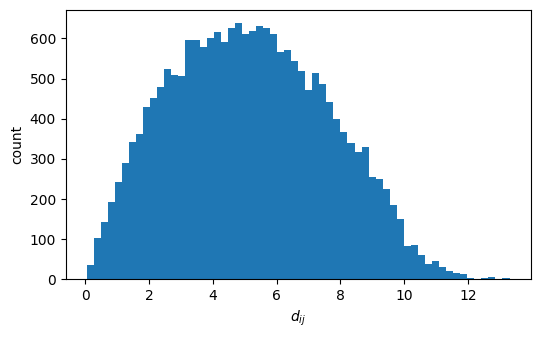

In [26]:
rng = np.random.default_rng(1)
N = 200
R = 10 * rng.random((N, 2))                   # positions: N rows, columns = (x, y)

# all difference vectors r_i - r_j at once.
# R[:, None, :] has shape (N, 1, 2), R[None, :, :] has shape (1, N, 2); broadcasting gives (N, N, 2).
diff = R[:, None, :] - R[None, :, :]

# lengths of the difference vectors -> distance matrix of shape (N, N)
D = np.sqrt(np.sum(diff**2, axis=-1))         # axis=-1 = the last axis (the x, y components)

# every pair once: triu_indices(N, k=1) gives the (row, column) indices above the diagonal, i.e. i < j.
iu = np.triu_indices(N, k=1)
# iu is a pair (rows, columns) of integer arrays; D[iu] picks D[rows[k], cols[k]] for every k
d = D[iu]                                     # 1D array of N(N-1)/2 distances
print("number of pairs:", d.size, "= N(N-1)/2 =", N * (N - 1) // 2)

# Lennard-Jones energy 4 eps [(sigma/d)^12 - (sigma/d)^6] summed over all pairs, in reduced units
# eps = sigma = 1 (lengths in units of sigma, energies in units of eps). Box size 10 and N = 200 are arbitrary.
E_LJ = np.sum(4 * (d**-12 - d**-6))
print(f"LJ energy: {E_LJ:.4g}   (closest pair at distance {d.min():.3f})")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(d, bins=60); ax.set_xlabel("$d_{ij}$"); ax.set_ylabel("count")
plt.show()
# The energy is huge and positive: for random positions some pairs are much closer than the LJ
# minimum at 2^(1/6) ~ 1.12, and the repulsive d^-12 term dominates.

### Exercise 5 (advanced) — A network with two hidden layers
1. Using `dense`, build a network $1 \to 32 \to 32 \to 1$ with $\tanh$ activations in hidden layers and a linear output.
   Initialise the weights from the normal distribution
$$W_{ij} \sim \mathcal N\Big(0, \frac{1}{n_\text{in}}\Big), \tag{32}$$
   whose second argument is the *variance*, so that the standard deviation passed to `rng.normal` is $1/\sqrt{n_\text{in}}$, and set the biases to zero. Evaluate the network on a batch of 500 points in $[-3, 3]$ and plot.
2. Count the total number of parameters (all entries of all $W$ and $b$). Derive the general formula for a network $n_0\to n_1\to\cdots\to n_L$.
3. Repeat with the standard deviation $5/\sqrt{n_\text{in}}$ instead of $1/\sqrt{n_\text{in}}$. Plot a histogram of the hidden activations of the second layer in both cases.
   What happens to the neurons ("saturation")? Why could this be bad for training? (We will come back to this — *weight initialisation*.)

#### Solution

number of parameters:

 1153   formula sum_l n_l (n_{l-1} + 1) = 1153


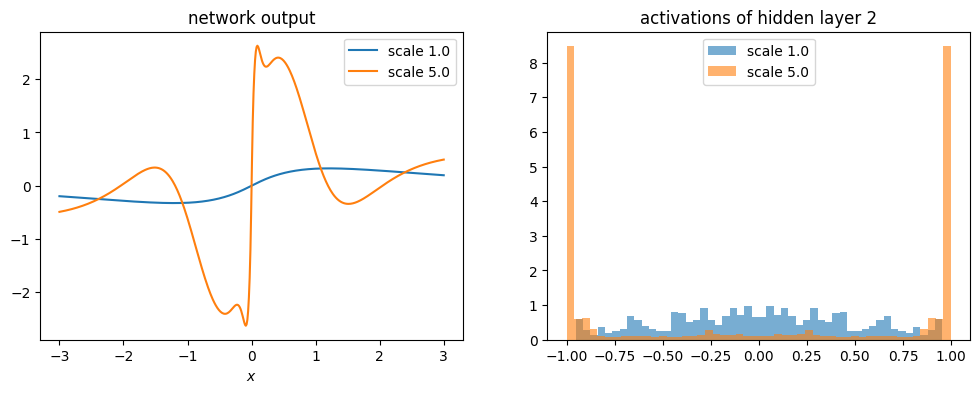

In [27]:
def init_layer(n_in, n_out, scale, rng):
    """Weights ~ N(0, (scale/sqrt(n_in))^2), shape (n_out, n_in); biases = 0."""
    W = rng.normal(0, scale / np.sqrt(n_in), (n_out, n_in))
    b = np.zeros(n_out)
    return W, b

X = np.linspace(-3, 3, 500)[:, None]          # batch of 500 inputs, shape (500, 1)
sizes = [1, 32, 32, 1]                        # layer widths n_0, n_1, n_2, n_3

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for scale in [1.0, 5.0]:
    # the generator is re-created with the same seed, so both networks get exactly the same random numbers,
    # only multiplied by a different factor: any difference between the two cases is caused by the scale alone
    rng = np.random.default_rng(0)
    # one (W, b) pair per consecutive pair of widths: (1->32), (32->32), (32->1).
    # zip(sizes[:-1], sizes[1:]) pairs each width with the next one; [... for ...] is a list comprehension,
    # which builds a list by evaluating the expression for every pair
    params = [init_layer(n_in, n_out, scale, rng) for n_in, n_out in zip(sizes[:-1], sizes[1:])]

    H1 = dense(X, *params[0], np.tanh)        # *params[0] unpacks the pair into W, b
    H2 = dense(H1, *params[1], np.tanh)
    Y = dense(H2, *params[2], lambda s: s)    # linear output layer (identity activation)

    axes[0].plot(X, Y, label=f"scale {scale}")
    # ravel() flattens the (500, 32) array to 1D, so all activations enter one histogram;
    # density=True scales the bars to total area 1, alpha=0.6 makes overlapping bars transparent
    axes[1].hist(H2.ravel(), bins=50, alpha=0.6, density=True, label=f"scale {scale}")

# Parameter count: layer l has n_l * n_{l-1} weights and n_l biases
n_params = sum(W.size + b.size for W, b in params)  # the same construct as a list comprehension, without brackets
formula = sum(n_out * (n_in + 1) for n_in, n_out in zip(sizes[:-1], sizes[1:]))
print("number of parameters:", n_params, "  formula sum_l n_l (n_{l-1} + 1) =", formula)

axes[0].set_title("network output"); axes[0].set_xlabel("$x$"); axes[0].legend()
axes[1].set_title("activations of hidden layer 2"); axes[1].legend()
plt.show()
# In the histogram, scale 1 spreads the activations over (-1, 1) (only about 1% have |h| > 0.95), while with
# scale 5 they pile up at -1 and +1 (about 69% have |h| > 0.95).
# With scale 5 most tanh units sit at +-1 (saturated). Their derivative 1 - tanh^2 is then close to 0,
# so gradients passing through them are tiny and training becomes very slow. Both runs scale the weights
# with 1/sqrt(n_in); what matters is the prefactor, chosen so that the pre-activations W z + b have a
# variance of order 1 (this particular choice is LeCun initialisation; the closely related Xavier/Glorot and He
# schemes use variances 2/(n_in + n_out) and 2/n_in).